**Regresión Logística - Histórico de Ventas CLV**

Se parte de `historico_ventas_clv_listo.csv`, se crea la variable dicotómica de mayor valor de negocio y se ajusta el modelo de clasificación aplicando reponderación de clases y sobremuestreo.

In [1]:
#Cargamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [2]:
#Cargar archivo csv con el dataset ya pre-procesado
df= pd.read_csv("historico_ventas_clv_listo.csv")
df.head(5)

,precio_unitario,total_unidades,total_neto,mes,dia_semana,dia_mes,folio_abreviado_B00,folio_abreviado_CDF,folio_abreviado_CP0,folio_abreviado_XDF,...,vendedor_LUISMAC,vendedor_MARIFER,vendedor_NAYELI,vendedor_NAYELI_BO_RODRIGO,vendedor_PIETRO,vendedor_RENE,vendedor_RENE_BO_YAMEL,vendedor_SERGIO_SANCHEZ,vendedor_SERV_TEC,vendedor_infrequent_sklearn
0,1.041704,-0.501647,0.210018,1.733802,0.724458,-0.161285,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


**Definición de la variable dicotómica**

Se evaluaron tres opciones a partir de las columnas disponibles:

| Variable candidata | Valor para CLV |
|---|---|
| `venta_premium`: la línea está en el 25% de mayor monto facturado | Permite anticipar donde se concentra el ingreso y dirigir inventario, visitas y promociones a las combinaciones de marca, zona, canal y vendedor que generan ticket alto |
| `es_mayoreo`: la venta fue de más de una pieza | Útil para venta cruzada, pero tras el recorte de outliers por IQR las unidades quedaron entre 1 y 3, así que casi no hay variación que modelar |
| `venta_fin_de_mes`: la venta ocurrió en la última semana del mes | Solo describe el calendario, no una decisión comercial |

Se elige **`venta_premium`**. CLV vende a doctores y consultorios con tickets muy dispares, desde un consumible de unos cientos de pesos hasta kits de equipo. Saber de antemano que combinaciones comerciales producen una línea de alto monto es lo que permite decidir donde poner el esfuerzo de venta.

El corte se hace en el tercer cuartil del total neto, lo que deja un 25% de casos positivos contra 75% de negativos. El desbalance es justo el escenario donde hacen falta las técnicas de reponderación y sobremuestreo.

In [3]:
#Obtenemos el límite para definir la clase: tercer cuartil del total neto
Limite= df['total_neto'].quantile(0.75)
Limite

np.float64(0.2896378626824369)

In [4]:
#Creamos la variable dicotómica a partir de la columna numérica
df['venta_premium']= np.where(df['total_neto'] > Limite, 1, 0)
df[['total_neto', 'venta_premium']].head()

,total_neto,venta_premium
0,0.210018,0
1,-0.530421,0
2,-0.530421,0
3,-0.530421,0
4,-0.530421,0


In [5]:
#Analizamos las categorias de la nueva columna
Categorias_Venta = df.groupby(['venta_premium'])['venta_premium'].count()
print(Categorias_Venta)
print(df['venta_premium'].value_counts(normalize=True).round(4))

venta_premium
0    16225
1     5407
Name: venta_premium, dtype: int64
venta_premium
0    0.75
1    0.25
Name: proportion, dtype: float64


Text(0.5, 1.0, 'Distribución de la variable venta_premium')

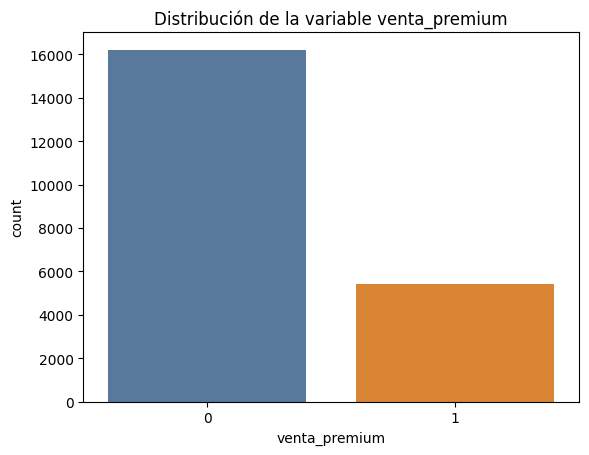

In [6]:
#Visualizamos el desbalance de clases
sns.countplot(x='venta_premium', data=df, palette=['#4C78A8', '#F58518'], hue='venta_premium', legend=False)
plt.title('Distribución de la variable venta_premium')

In [7]:
#Guardamos la base con la variable dicotómica incluida
df.to_csv("historico_ventas_clv_premium.csv", index=False)

**Selección de variables independientes**

Se excluyen `total_neto`, `precio_unitario` y `total_unidades`. El total neto es el monto con el que se construyó la clase y los otros dos son sus factores (precio por unidades), así que el modelo acertaría por definición sin aportar información.

Quedan las variables que CLV conoce antes de cerrar la venta: marca, estado, vendedor, canal de facturación (`folio_abreviado`) y la temporalidad. El modelo responde entonces a una pregunta útil: dado el contexto comercial de la operación, que probabilidad hay de que sea una venta de ticket alto.

In [8]:
#Declaramos las variables dependientes e independientes para la regresión Logística
Vars_Indep= df.drop(columns=['total_neto', 'precio_unitario', 'total_unidades', 'venta_premium'])
Var_Dep= df['venta_premium']

#Redefinimos las variables
X= Vars_Indep
y= Var_Dep
print(X.shape)
X.columns.tolist()

(21632, 64)


['mes',
 'dia_semana',
 'dia_mes',
 'folio_abreviado_B00',
 'folio_abreviado_CDF',
 'folio_abreviado_CP0',
 'folio_abreviado_XDF',
 'folio_abreviado_XP0',
 'folio_abreviado_infrequent_sklearn',
 'marca_AIDITE',
 'marca_HUGE',
 'marca_JENSE',
 'marca_MEDIT',
 'marca_VITA',
 'marca_infrequent_sklearn',
 'estado_BAJA_CALIFORNIA',
 'estado_CHIHUAHUA',
 'estado_CIUDAD_DE_MEXICO',
 'estado_COAHUILA',
 'estado_DURANGO',
 'estado_ESTADO_DE_MEXICO',
 'estado_GUANAJUATO',
 'estado_GUERRERO',
 'estado_HIDALGO',
 'estado_JALISCO',
 'estado_MICHOACAN',
 'estado_MORELOS',
 'estado_NUEVO_LEON',
 'estado_OAXACA',
 'estado_PUEBLA',
 'estado_QUERETARO',
 'estado_QUINTANA_ROO',
 'estado_SAN_LUIS_POTOSI',
 'estado_SONORA',
 'estado_TAMAULIPAS',
 'estado_TLAXCALA',
 'estado_VERACRUZ',
 'estado_YUCATAN',
 'estado_infrequent_sklearn',
 'vendedor_ANGESAL',
 'vendedor_BO_CLAUDIA',
 'vendedor_BO_EDGAR',
 'vendedor_CARLOST',
 'vendedor_DIEGO',
 'vendedor_ERICKJUA',
 'vendedor_ESMERALDA',
 'vendedor_FERNANDOCRU_B

In [9]:
#Dividimos el conjunto de datos en la parte de entrenamiento y prueba de forma estratificada
#stratify=y conserva la proporción 75/25 de las clases en los dos conjuntos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print('Entrenamiento:', X_train.shape, 'Prueba:', X_test.shape)

Entrenamiento: (15142, 64) Prueba: (6490, 64)


In [10]:
#Verificamos que la estratificación conservó la proporción de clases
pd.DataFrame({
    'completo': y.value_counts(normalize=True),
    'entrenamiento': y_train.value_counts(normalize=True),
    'prueba': y_test.value_counts(normalize=True),
}).round(4)

,completo,entrenamiento,prueba
venta_premium,,,
0,0.75,0.75,0.7501
1,0.25,0.25,0.2499


No se aplica `StandardScaler` porque las variables numéricas ya quedaron estandarizadas en el pre-procesamiento y el resto son columnas 0/1.

**Modelo base sin tratamiento del desbalance**

In [11]:
#Definimos el algoritmo a utilizar
algoritmo = LogisticRegression(max_iter=1000)

#Entrenamos el modelo
algoritmo.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [12]:
#Realizamos una predicción
y_pred = algoritmo.predict(X_test)
y_pred

array([1, 0, 0, ..., 0, 0, 1], shape=(6490,))

In [13]:
#Verifico la matriz de Confusión
from sklearn.metrics import confusion_matrix
matriz = confusion_matrix(y_test, y_pred)
print('Matriz de Confusión:')
print(matriz)

Matriz de Confusión:
[[4466  402]
 [1131  491]]


In [14]:
#Calculo las métricas del modelo
from sklearn.metrics import precision_score, accuracy_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
print('Precisión del modelo:')
print(precision)

exactitud = accuracy_score(y_test, y_pred)
print('Exactitud del modelo:')
print(exactitud)

sensibilidad = recall_score(y_test, y_pred)
print('Sensibilidad del modelo:')
print(sensibilidad)

puntajef1 = f1_score(y_test, y_pred)
print('Puntaje F1 del modelo:')
print(puntajef1)

Precisión del modelo:
0.5498320268756999
Exactitud del modelo:
0.7637904468412943
Sensibilidad del modelo:
0.3027127003699137
Puntaje F1 del modelo:
0.3904572564612326


La exactitud de 0.764 se ve bien pero engaña: el modelo solo detecta el 30% de las ventas premium (sensibilidad 0.303). Al estar la clase positiva en minoría, al algoritmo le conviene contestar "no premium" casi siempre. Para CLV eso significa dejar pasar 7 de cada 10 oportunidades de ticket alto, que es justo lo que se quería identificar.

***Método 1 Reponderación de las Clases***

In [15]:
#Reponderación de las clases
algoritmo_Pond = LogisticRegression(max_iter=1000, class_weight='balanced')
algoritmo_Pond.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [16]:
#Realizamos una predicción
y_pred_pond = algoritmo_Pond.predict(X_test)

#Verifico la matriz de Confusión
matriz_pond = confusion_matrix(y_test, y_pred_pond)
print('Matriz de Confusión:')
print(matriz_pond)

Matriz de Confusión:
[[3273 1595]
 [ 354 1268]]


In [17]:
#Calculo las métricas del modelo reponderado
print('Precisión del modelo:')
print(precision_score(y_test, y_pred_pond))

print('Exactitud del modelo:')
print(accuracy_score(y_test, y_pred_pond))

print('Sensibilidad del modelo:')
print(recall_score(y_test, y_pred_pond))

print('Puntaje F1 del modelo:')
print(f1_score(y_test, y_pred_pond))

Precisión del modelo:
0.44289207125392943
Exactitud del modelo:
0.6996918335901386
Sensibilidad del modelo:
0.781750924784217
Puntaje F1 del modelo:
0.5654403567447046


***Método 2 Sobremuestreo (Oversampling con SMOTE)***

In [18]:
#Aplicamos la técnica de sobremuestreo (oversampling)
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)
y_resampled.value_counts()

venta_premium
0    11357
1    11357
Name: count, dtype: int64

In [19]:
#Entrenamos el modelo sobremuestreado
algoritmo_Over_sampling = LogisticRegression(max_iter=1000)
algoritmo_Over_sampling.fit(X_resampled, y_resampled)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [20]:
#Realizamos una predicción
y_pred_over_sampling = algoritmo_Over_sampling.predict(X_test)

#Verifico la matriz de Confusión
matriz_over = confusion_matrix(y_test, y_pred_over_sampling)
print('Matriz de Confusión:')
print(matriz_over)

Matriz de Confusión:
[[3381 1487]
 [ 380 1242]]


In [21]:
#Calculo las métricas del modelo sobremuestreado
print('Precisión del modelo:')
print(precision_score(y_test, y_pred_over_sampling))

print('Exactitud del modelo:')
print(accuracy_score(y_test, y_pred_over_sampling))

print('Sensibilidad del modelo:')
print(recall_score(y_test, y_pred_over_sampling))

print('Puntaje F1 del modelo:')
print(f1_score(y_test, y_pred_over_sampling))

Precisión del modelo:
0.45511176255038477
Exactitud del modelo:
0.712326656394453
Sensibilidad del modelo:
0.7657213316892725
Puntaje F1 del modelo:
0.570903240634337


**Análisis de clasificación**

In [22]:
#Comparamos las métricas de los tres modelos sobre el mismo conjunto de prueba
Resultados= []
for nombre, pred in [('Base', y_pred), ('Reponderación', y_pred_pond), ('Oversampling SMOTE', y_pred_over_sampling)]:
    Resultados.append({
        'modelo': nombre,
        'exactitud': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'sensibilidad': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
    })

pd.DataFrame(Resultados).round(4)

,modelo,exactitud,precision,sensibilidad,f1
0,Base,0.7638,0.5498,0.3027,0.3905
1,Reponderación,0.6997,0.4429,0.7818,0.5654
2,Oversampling SMOTE,0.7123,0.4551,0.7657,0.5709


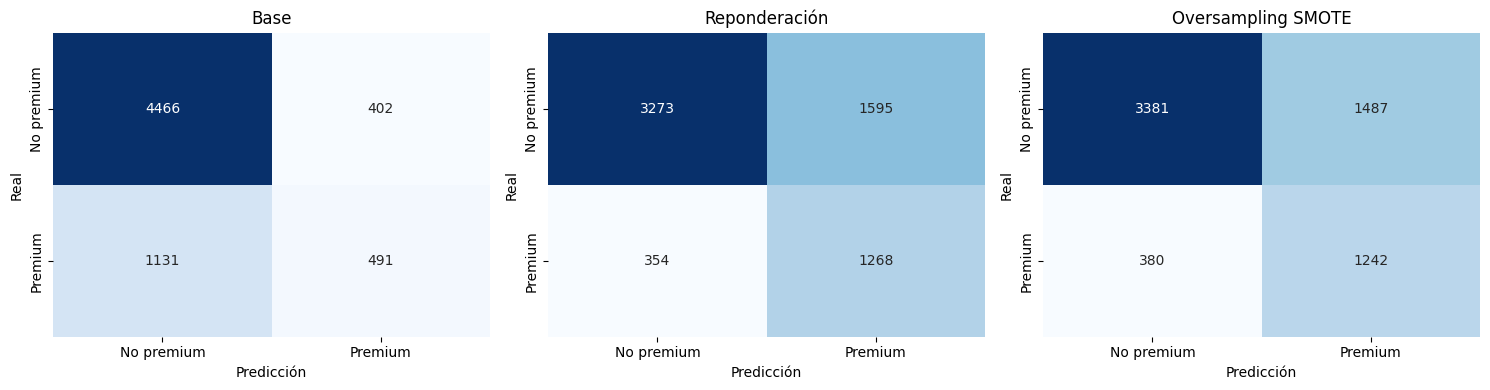

In [23]:
#Visualizamos las tres matrices de confusión
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a, (nombre, m) in zip(ax, [('Base', matriz), ('Reponderación', matriz_pond), ('Oversampling SMOTE', matriz_over)]):
    sns.heatmap(m, annot=True, fmt='d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['No premium', 'Premium'], yticklabels=['No premium', 'Premium'])
    a.set_title(nombre)
    a.set_xlabel('Predicción')
    a.set_ylabel('Real')
plt.tight_layout()
plt.show()

In [24]:
#Revisamos los coeficientes del modelo balanceado para la lectura de negocio
Coeficientes= pd.Series(algoritmo_Pond.coef_[0], index=X.columns).sort_values(ascending=False)
print('Mayor probabilidad de venta premium:')
print(Coeficientes.head(8).round(3))
print()
print('Menor probabilidad de venta premium:')
print(Coeficientes.tail(8).round(3))

Mayor probabilidad de venta premium:
estado_DURANGO         1.473
estado_GUANAJUATO      1.217
estado_JALISCO         1.046
estado_TAMAULIPAS      1.000
estado_CHIHUAHUA       0.927
estado_SONORA          0.850
folio_abreviado_CDF    0.841
estado_HIDALGO         0.834
dtype: float64

Menor probabilidad de venta premium:
folio_abreviado_XP0        -0.496
vendedor_LUIS_BO_CLAUDIA   -0.584
vendedor_JAVIERCAD         -0.732
vendedor_ESMERALDA         -0.854
marca_JENSE                -1.175
marca_MEDIT                -1.477
marca_VITA                 -1.958
marca_HUGE                 -4.248
dtype: float64


**Lectura de los resultados**

Las cuatro métricas sobre el conjunto de prueba (6,490 líneas, 1,622 de ellas premium):

| Modelo | Exactitud | Precisión | Sensibilidad | F1 |
|---|---|---|---|---|
| Base | 0.764 | 0.550 | 0.303 | 0.390 |
| Reponderación de clases | 0.700 | 0.443 | 0.782 | 0.565 |
| Oversampling SMOTE | 0.712 | 0.455 | 0.766 | 0.571 |

**Matriz de confusión.** De las 1,622 líneas premium reales, el modelo base solo detecta 491 y deja pasar 1,131. Con reponderación los verdaderos positivos suben de 491 a 1,268, es decir 777 ventas de ticket alto más, a cambio de que los falsos positivos pasen de 402 a 1,595.

**Exactitud.** Baja de 0.764 a 0.700. Es el intercambio esperado: el modelo base acertaba mucho simplemente porque contestar "no premium" es correcto el 75% de las veces.

**Precisión.** De 0.550 a 0.443. De cada 10 líneas que el modelo marca como premium, acierta en 4 o 5.

**Sensibilidad.** De 0.303 a 0.782, el cambio relevante. Es la métrica que importa en este caso: el costo de no detectar una venta de ticket alto (perder la oportunidad) es mayor que el de revisar una operación que al final resultó de monto normal.

**F1.** Pasa de 0.390 a 0.565 con reponderación y 0.571 con SMOTE, confirmando que el balance global mejora y no solo se desplazó el umbral.

Los dos métodos de balanceo dan resultados casi iguales. Conviene la **reponderación de clases** por ser una sola línea (`class_weight='balanced'`), sin generar registros sintéticos y sin dependencias extra.

**Lectura comercial de los coeficientes.** Los pesos más grandes son de marca y van en negativo, siempre contra la marca de referencia AG (fresas, 36.9% de sus líneas son premium): HUGE -4.25 (dientes de tablilla, 0% premium) y VITA -1.96 (consumible de ticket bajo, 7.5% premium). La única marca que sube la probabilidad es AIDITE, +0.58, con 47.1% de líneas premium. Del lado de la plaza pesan los estados del norte y el bajío (Durango +1.47, Guanajuato +1.22, Jalisco +1.05) y el canal CDF +0.84.

La conclusión operativa es que la marca y el canal mandan sobre la plaza y el vendedor: para subir el ticket promedio conviene mover el mix de catálogo antes que reasignar territorios.

**Un punto a tomar en cuenta.** MEDIT aparece con coeficiente negativo (-1.48) cuando en los datos originales es la marca de mayor ticket, con una mediana de 94,828 pesos (escáneres). El recorte de outliers por IQR del pre-procesamiento aplanó esas 334 líneas al valor de la mediana general, así que el modelo ya no las reconoce como premium. Es un efecto del tratamiento de outliers, no del negocio. Si el objetivo fuera modelar específicamente la venta de equipo, habría que repetir el pre-procesamiento con un criterio de outliers menos agresivo, por ejemplo 3·IQR o un recorte por percentiles.